<a href="https://colab.research.google.com/github/Awimya-Rn/PCVK26_13_Ilham/blob/main/week_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q "opencv-python-headless<5"

In [ ]:
import cv2 as cv
print(cv.__version__, hasattr(cv, "CascadeClassifier"))

4.14.0 True


# D1. Praktikum Deteksi Obyek Dasar

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Implementasikan 6 metode template matching pada OpenCV dengan menggunakan gambar cats_and_bunnies.jpg dan cat2_templatejpg.jpg sebagai citra template.

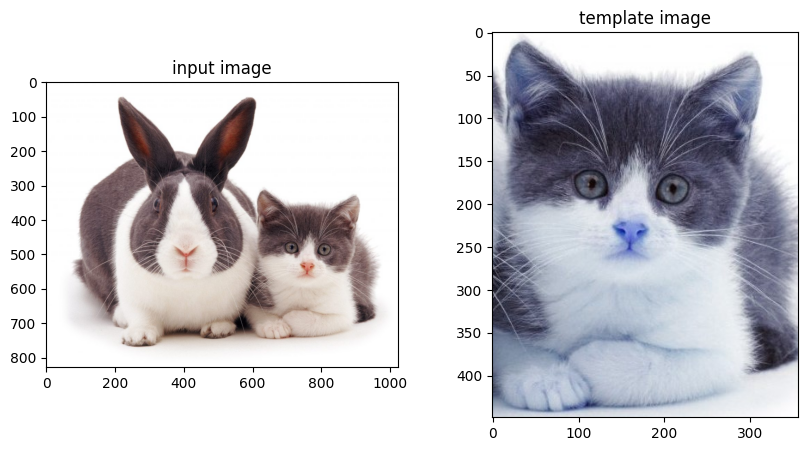

<Figure size 1200x2400 with 0 Axes>

<Figure size 1200x2400 with 0 Axes>

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection/cats_and_bunnies.jpg')
template = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection/cat2_templatejpg.jpg')

h, w = template.shape[:2]

methods = [
    'TM_SQDIFF',
    'TM_SQDIFF_NORMED',
    'TM_CCORR',
    'TM_CCORR_NORMED',
    'TM_CCOEFF',
    'TM_CCOEFF_NORMED'
]

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('input image')
plt.subplot(122)
plt.imshow(template, cmap='gray')
plt.title('template image')
plt.show()

plt.figure(figsize=(12, 24))

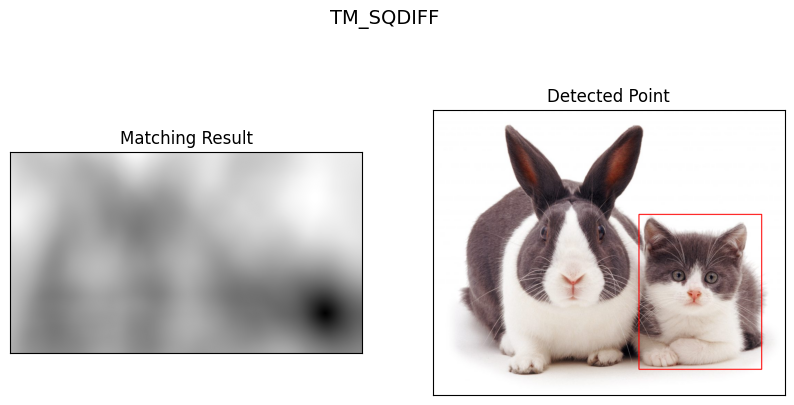

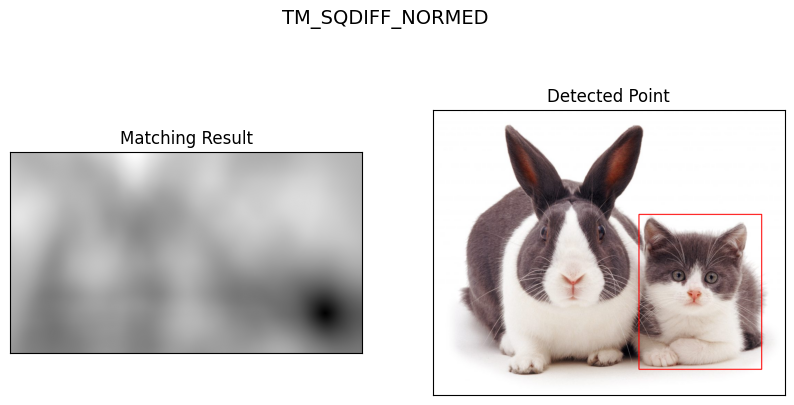

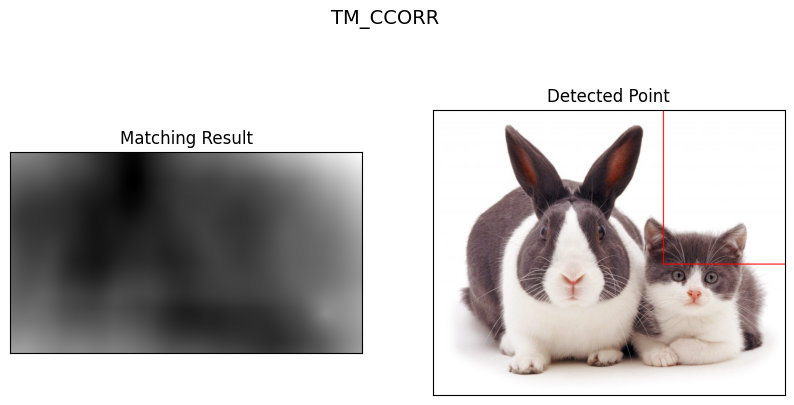

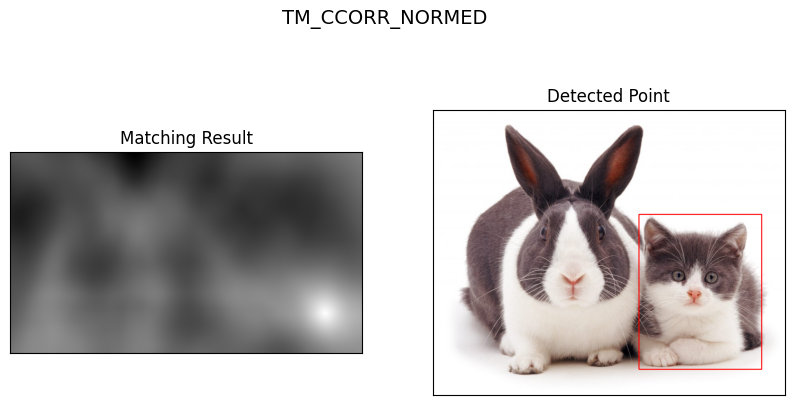

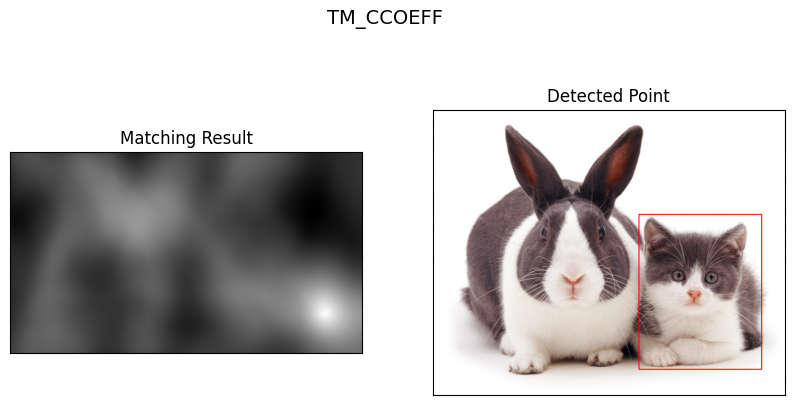

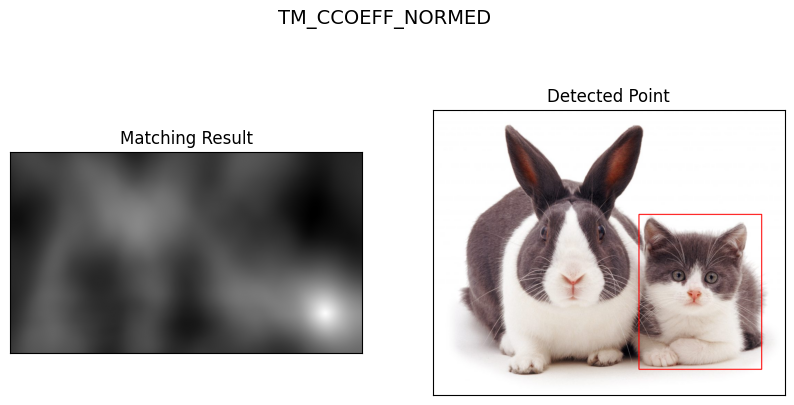

In [ ]:
for meth in methods:
    img_copy = img.copy()
    method = getattr(cv, meth.replace('cv.', ''))
    res = cv.matchTemplate(img_copy, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)

    cv.rectangle(img_copy, top_left, bottom_right, (0, 0, 255), 2)

    plt.figure(figsize=(10, 5))
    plt.subplot(121)
    plt.imshow(res, cmap='gray')
    plt.title('Matching Result')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122)
    plt.imshow(cv.cvtColor(img_copy, cv.COLOR_BGR2RGB))
    plt.title('Detected Point')
    plt.xticks([]), plt.yticks([])
    plt.suptitle(meth, fontsize=14)
    plt.show()

## 3. Implementasikan konsep template matching tanpa menggunakan library OpenCV untuk multiple object, menggunakan gambar bahrain.jpg untuk citra masukan dan bahraintemplate.jpg sebagai citra template

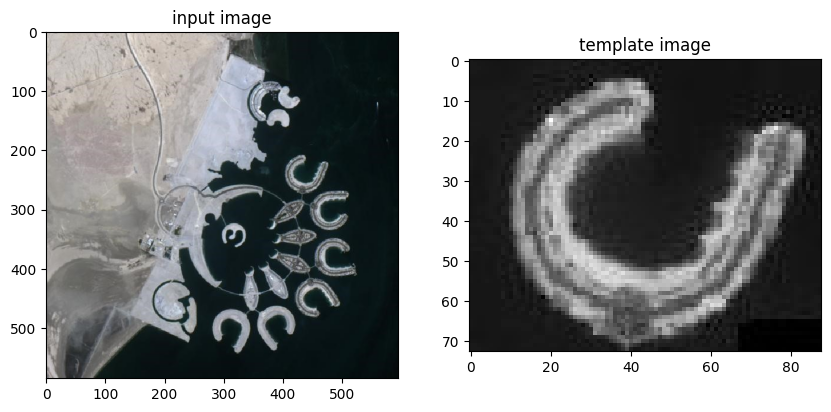

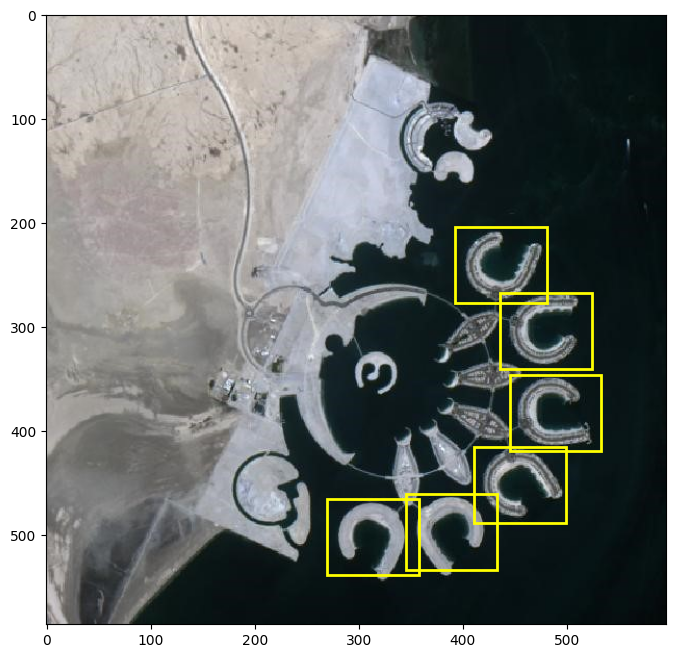

In [ ]:
import matplotlib.patches as patches
from PIL import Image
from numpy.lib.stride_tricks import sliding_window_view

img_rgb  = np.array(Image.open('/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection/bahrain.jpg').convert('RGB'))
img_gray = np.array(Image.open('/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection/bahrain.jpg').convert('L'), dtype=np.float64)
tpl_gray = np.array(Image.open('/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection/bahrain-template.jpg').convert('L'), dtype=np.float64)
h, w = tpl_gray.shape

def match_template_ncc(image, template):
    H, W = image.shape
    h, w = template.shape
    n = h * w
    t_zero = template - template.mean()
    t_norm = np.sqrt(np.sum(t_zero ** 2))
    result = np.zeros((H - h + 1, W - w + 1))

    for y in range(H - h + 1):
        strip = image[y:y + h, :]
        windows = sliding_window_view(strip, (h, w))[0]
        sum_w  = windows.sum(axis=(1, 2))
        sum_w2 = (windows ** 2).sum(axis=(1, 2))
        numerator = np.einsum('xij,ij->x', windows, t_zero)
        var_w = sum_w2 - (sum_w ** 2) / n
        denom = np.sqrt(np.maximum(var_w, 1e-12)) * t_norm
        result[y] = np.where(var_w > 1e-6, numerator / denom, 0)

    return result

def find_multiple_objects(result, tpl_shape, threshold):
    h, w = tpl_shape
    ys, xs = np.where(result >= threshold)
    scores = result[ys, xs]
    order = np.argsort(-scores)
    taken = np.zeros_like(result, dtype=bool)
    detections = []

    for idx in order:
        y, x = ys[idx], xs[idx]
        if taken[y, x]:
            continue
        detections.append((x, y, scores[idx]))
        taken[max(0, y - h // 2): y + h // 2 + 1,
              max(0, x - w // 2): x + w // 2 + 1] = True

    return detections

result = match_template_ncc(img_gray, tpl_gray)

THRESHOLD = 0.45
detections = find_multiple_objects(result, (h, w), THRESHOLD)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img_rgb)
plt.title('input image')
plt.subplot(122)
plt.imshow(tpl_gray, cmap='gray')
plt.title('template image')
plt.show()

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img_rgb)

for (x, y, s) in detections:
    ax.add_patch(patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='yellow', facecolor='none'))

plt.show()

## 4. Implementasikan metode Sobel Edge Detection, Canny Edge Detection, dan Laplacian Edge Detection pada OpenCV dengan menggunakan gambar car-park.jpg

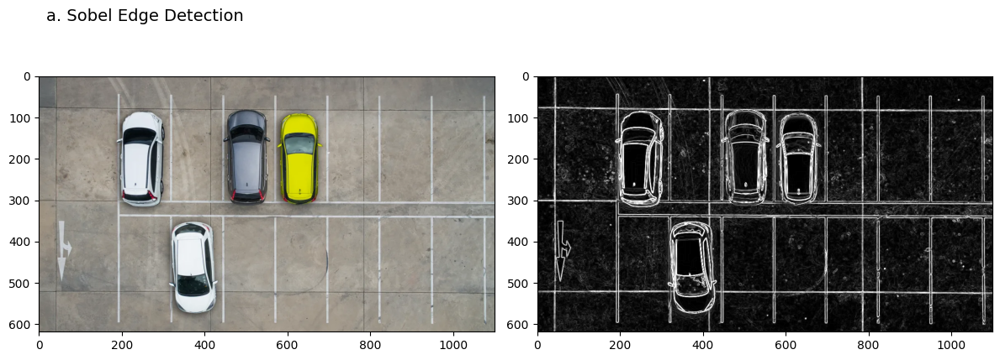

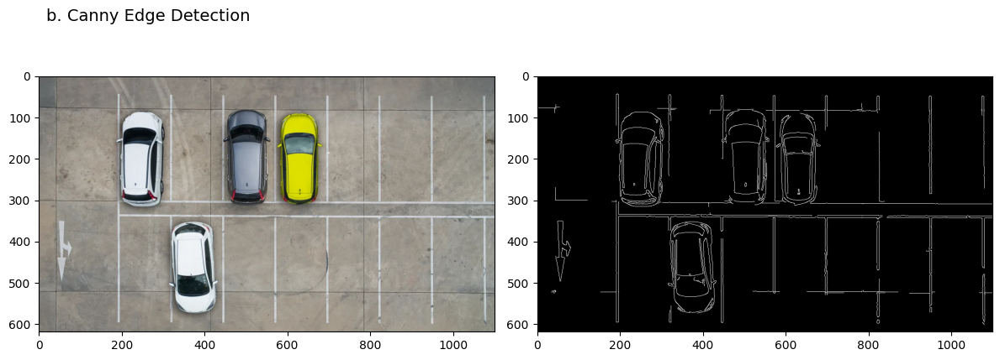

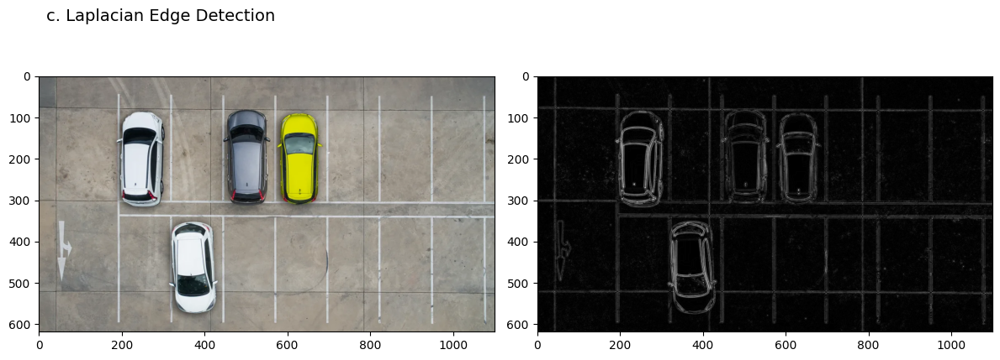

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection/car-park.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (5, 5), 0)

def tampilkan(hasil, judul):
    fig = plt.figure(figsize=(12, 4.5))
    plt.subplot(121)
    plt.imshow(img_rgb)
    plt.subplot(122)
    plt.imshow(hasil, cmap='gray')
    fig.suptitle(judul, x=0.05, ha='left', fontsize=14)
    plt.tight_layout()
    plt.show()

sobel_x = cv.Sobel(gray, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(gray, cv.CV_64F, 0, 1, ksize=3)
sobel = cv.convertScaleAbs(cv.magnitude(sobel_x, sobel_y))
tampilkan(sobel, 'a. Sobel Edge Detection')

canny = cv.Canny(blur, 100, 200)
tampilkan(canny, 'b. Canny Edge Detection')

laplacian = cv.Laplacian(blur, cv.CV_64F, ksize=3)
laplacian = cv.convertScaleAbs(laplacian)
tampilkan(laplacian, 'c. Laplacian Edge Detection')

## 5. Implementasikan metode Harris Corner Detection dan Shi-Tomasi Detection pada OpenCV dengan menggunakan gambar chessboard.jpg

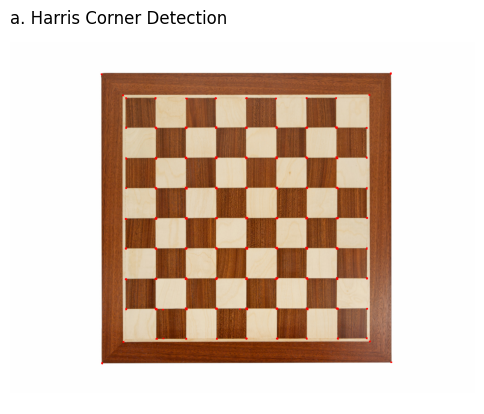

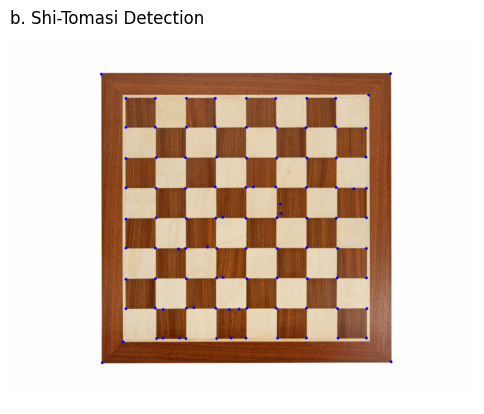

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection/chess-board.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

def tampilkan(hasil_bgr, judul):
    plt.figure(figsize=(6, 6))
    plt.imshow(cv.cvtColor(hasil_bgr, cv.COLOR_BGR2RGB))
    plt.title(judul, loc='left', fontsize=12)
    plt.axis('off')
    plt.show()

img_harris = img.copy()
gray_f = np.float32(gray)
dst = cv.cornerHarris(gray_f, 2, 3, 0.04)
dst = cv.dilate(dst, None)
img_harris[dst > 0.01 * dst.max()] = [0, 0, 255]
tampilkan(img_harris, 'a. Harris Corner Detection')

img_shi = img.copy()
corners = cv.goodFeaturesToTrack(gray, 100, 0.01, 10)
corners = corners.astype(int)
for c in corners:
    x, y = c.ravel()
    cv.circle(img_shi, (x, y), 3, (255, 0, 0), -1)

tampilkan(img_shi, 'b. Shi-Tomasi Detection')

## 6. Implementasikan metode Hough Transform pada OpenCV dengan menggunakan gambar sudoku.jpg. Tahapan proses grid detection sesuai yang terdapat pada ulasan teori

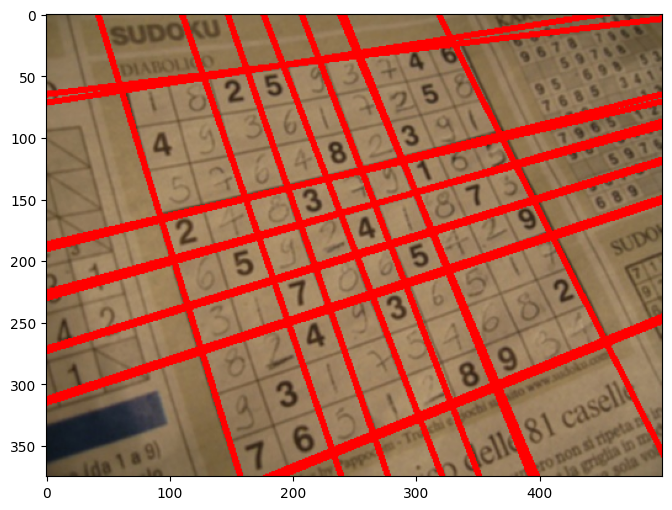

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection/sudoku.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(gray, (5, 5), 0)
edges = cv.Canny(blur, 50, 150, apertureSize=3)
lines = cv.HoughLines(edges, 1, np.pi / 180, 150)
hasil = img.copy()

if lines is not None:
    for line in lines:
        rho, theta = line[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * a)
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * a)
        cv.line(hasil, (x1, y1), (x2, y2), (0, 0, 255), 3)
else:
    print('Tidak ada garis terdeteksi, turunkan nilai threshold.')

plt.figure(figsize=(8, 6))
plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
plt.show()

## 7. Implementasikan fungsi findContours() pada OpenCV untuk contour detection dengan menggunakan gambar laptop.jpg

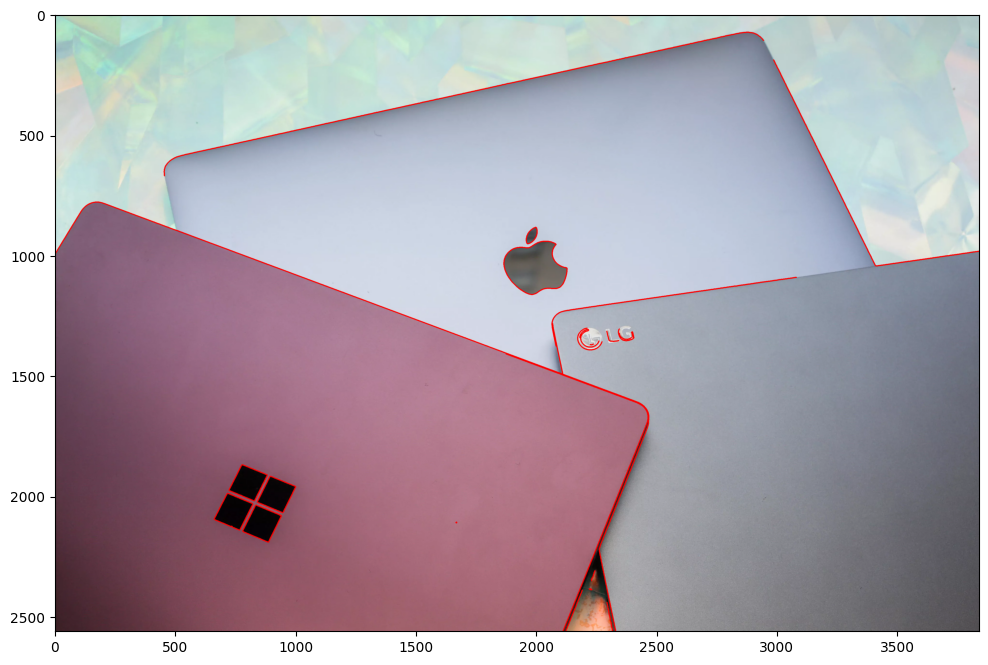

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection/laptop.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (5, 5), 0)
edges = cv.Canny(blur, 100, 200)
contours, hierarchy = cv.findContours(edges, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

hasil = img.copy()
cv.drawContours(hasil, contours, -1, (0, 0, 255), 3)
plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
plt.show()

# D2. Praktikum Feature Matching dan Face Detection

## 8. Lakukan Face Detection untuk image object lain yang tersedia pada (/images/facedet).

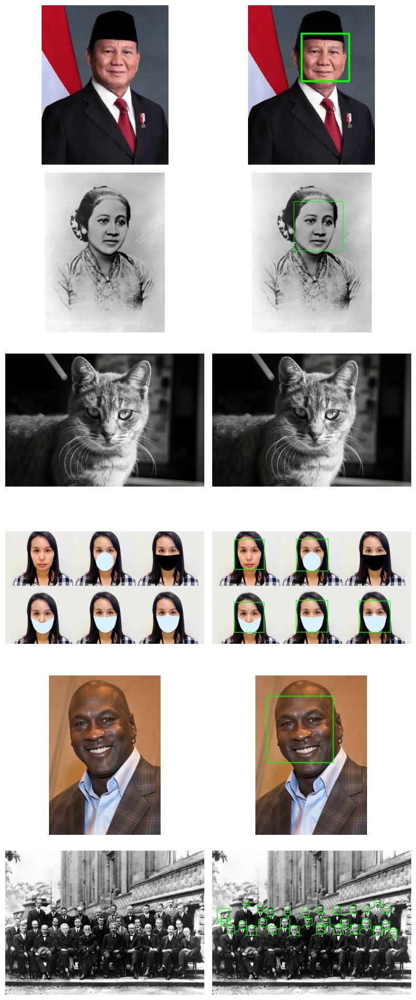

In [ ]:
IMAGE_DIR = "/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection"
IMAGE_FILES = ["prabowo.jpg", "rakartini.jpg", "kucing.jpg", "bermasker.jpg", "Michael_Jordan.jpg", "Solvay_conference.jpg"]

PARAMS = {
    "prabowo.jpg": (1.1, 5, (40, 40)),
    "rakartini.jpg": (1.1, 5, (40, 40)),
    "kucing.jpg": (1.1, 5, (40, 40)),
    "bermasker.jpg": (1.1, 5, (40, 40)),
    "Michael_Jordan.jpg": (1.1,  5, (40, 40)),
    "Solvay_conference.jpg": (1.05, 5, (15, 15)),
}

MAX_SIDE = 900

cascade = cv.CascadeClassifier(cv.data.haarcascades + "haarcascade_frontalface_alt2.xml")
assert not cascade.empty(), "Gagal memuat cascade"

fig, axes = plt.subplots(len(IMAGE_FILES), 2, figsize=(8, 3.2 * len(IMAGE_FILES)))

for i, fname in enumerate(IMAGE_FILES):
    img = cv.imread(f"{IMAGE_DIR}/{fname}")
    if img is None:
        print(f"[!] Gagal membaca {fname}")
        axes[i, 0].axis("off"); axes[i, 1].axis("off")
        continue

    scale = MAX_SIDE / max(img.shape[:2])
    if scale < 1:
        img = cv.resize(img, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA)

    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    sf, mn, ms = PARAMS[fname]
    faces = cascade.detectMultiScale(gray, scaleFactor=sf, minNeighbors=mn, minSize=ms)

    out = img.copy()
    t = max(2, int(min(out.shape[:2]) / 250))
    for (x, y, w, h) in faces:
        cv.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), t)

    axes[i, 0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    axes[i, 0].axis("off")
    axes[i, 1].imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB))
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

## 9. Pada soal sebelumnya, wajah kucing tidak bisa dideteksi dengan baik. Lakukan deteksi wajah kucing hingga muncul rectangle pada bagian wajah kucing. Petunjuk pada soal ini, perhatikan pretrained features yang telah disediakan OpenCV. Gunakan xml yang ada jika memang telah disediakan.

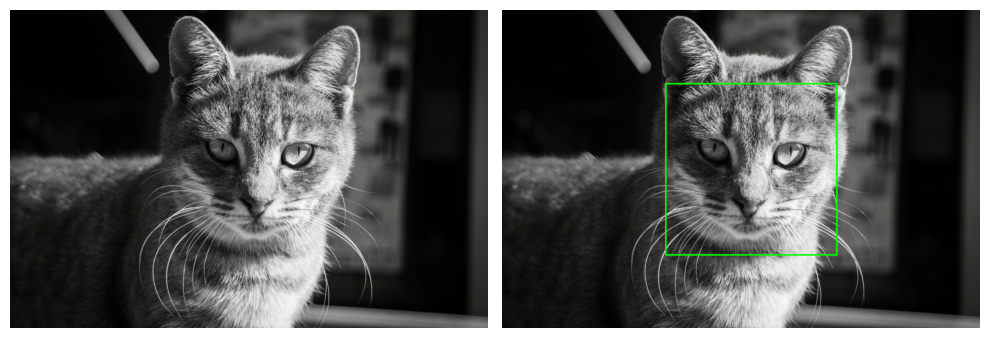

In [ ]:
cat_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + "haarcascade_frontalcatface_extended.xml")
assert not cat_cascade.empty(), "Gagal memuat cascade wajah kucing"

img = cv.imread(f"/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection/kucing.jpg")
assert img is not None, "Gagal membaca gambar"

scale = MAX_SIDE / max(img.shape[:2])
if scale < 1:
    img = cv.resize(img, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA)

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

faces = cat_cascade.detectMultiScale(gray, scaleFactor=1.02, minNeighbors=4, minSize=(75, 75))

out = img.copy()
t = max(2, int(min(out.shape[:2]) / 250))
for (x, y, w, h) in faces:
    cv.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), t)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
axes[0].axis("off")
axes[1].imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB))
axes[1].axis("off")
plt.tight_layout()
plt.show()

## 10.Cobakan juga untuk eyes detection pada wajah Pak Prabowo

2 mata terdeteksi


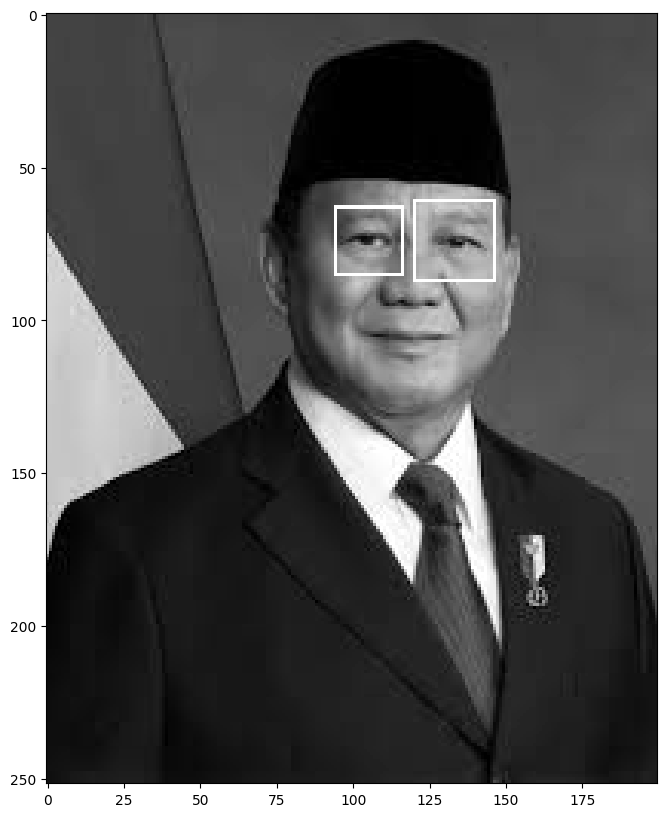

In [ ]:
IMAGE_PATH = "/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection/prabowo.jpg"
XML_PATH = cv.data.haarcascades + "haarcascade_eye.xml"

cascade_mata = cv.CascadeClassifier(XML_PATH)
assert not cascade_mata.empty(), "Gagal memuat cascade mata"

prabowo = cv.imread(IMAGE_PATH, 0)
assert prabowo is not None, "Gagal membaca gambar"

roi_mata = cascade_mata.detectMultiScale(prabowo)
print(f"{len(roi_mata)} mata terdeteksi")

for (x, y, w, h) in roi_mata:
    cv.rectangle(prabowo, (x, y), (x + w, y + h), (255, 255, 255), 1)

plt.figure(figsize=(10, 10))
plt.imshow(prabowo, cmap="gray")
plt.show()

## 11.Lakukan deteksi senyuman pada gambar people:

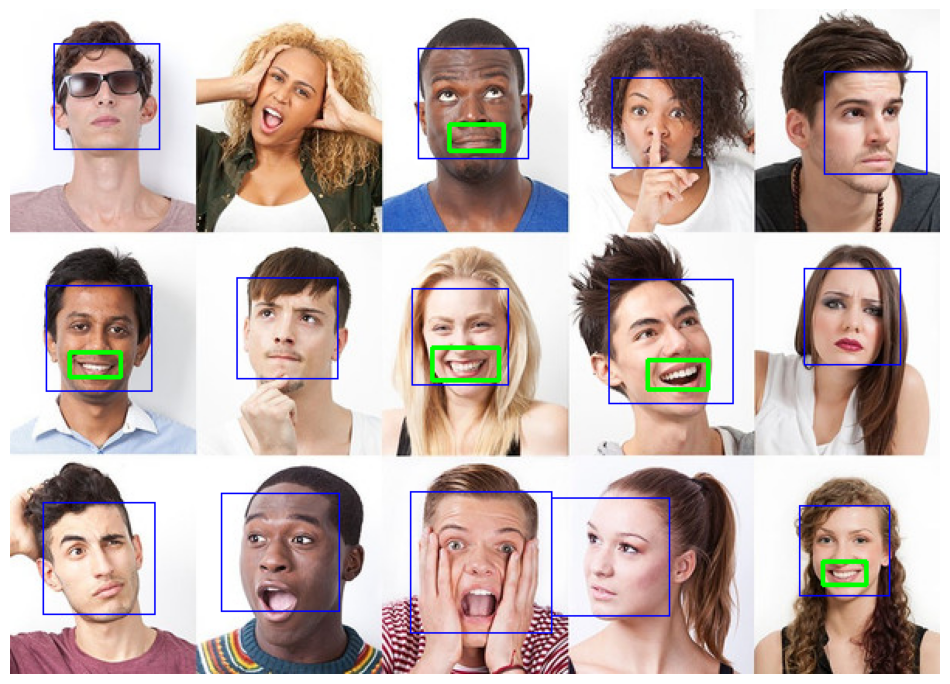

In [ ]:
face_cascade  = cv.CascadeClassifier(cv.data.haarcascades + "haarcascade_frontalface_alt2.xml")
smile_cascade = cv.CascadeClassifier(cv.data.haarcascades + "haarcascade_smile.xml")
assert not face_cascade.empty() and not smile_cascade.empty(), "Gagal memuat cascade"

img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection/smile.jpg')
assert img is not None, "Gagal membaca gambar"
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
out = img.copy()

faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))

n_smile = 0
for (x, y, w, h) in faces:
    cv.rectangle(out, (x, y), (x + w, y + h), (255, 0, 0), 1)

    roi = gray[y + h // 2 : y + h, x : x + w]
    k = 200.0 / w
    roi_big = cv.resize(roi, None, fx=k, fy=k, interpolation=cv.INTER_CUBIC)

    rects, _, weights = smile_cascade.detectMultiScale3(
        roi_big, scaleFactor=1.4, minNeighbors=25,
        minSize=(40, 20), outputRejectLevels=True)
    if len(rects) == 0:
        continue

    sx, sy, sw, sh = rects[int(weights.argmax())]
    n_smile += 1

    x1, y1 = x + int(sx / k), y + h // 2 + int(sy / k)
    x2, y2 = x + int((sx + sw) / k), y + h // 2 + int((sy + sh) / k)
    cv.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.figure(figsize=(12, 9))
plt.imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## 12.Lakukan Face Tracking menggunakan Google Colab. Petunjuk, Tutorial lengkap tentang akses kamera dan FaceDetection pada google colab dapat dilihat di link berikut: https://www.youtube.com/watch?v=YjWh7QvVH60

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode, b64encode
from PIL import Image as PILImage
import io
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

face_cascade = cv.CascadeClassifier(cv.data.haarcascades + "haarcascade_frontalface_alt2.xml")
assert not face_cascade.empty(), "Gagal memuat cascade wajah"

SF, MN, MS = 1.1, 5, (60, 60)

def detect_faces(gray):
    return face_cascade.detectMultiScale(gray, scaleFactor=SF, minNeighbors=MN, minSize=MS)

def js_to_image(js_reply):
    image_bytes = b64decode(js_reply.split(',')[1])
    jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
    return cv.imdecode(jpg_as_np, flags=1)

def bbox_to_bytes(bbox_array):
    bbox_pil = PILImage.fromarray(bbox_array, 'RGBA')
    iobuf = io.BytesIO()
    bbox_pil.save(iobuf, format='png')
    return 'data:image/png;base64,{}'.format(str(b64encode(iobuf.getvalue()), 'utf-8'))

<IPython.core.display.Javascript object>

1 wajah terdeteksi


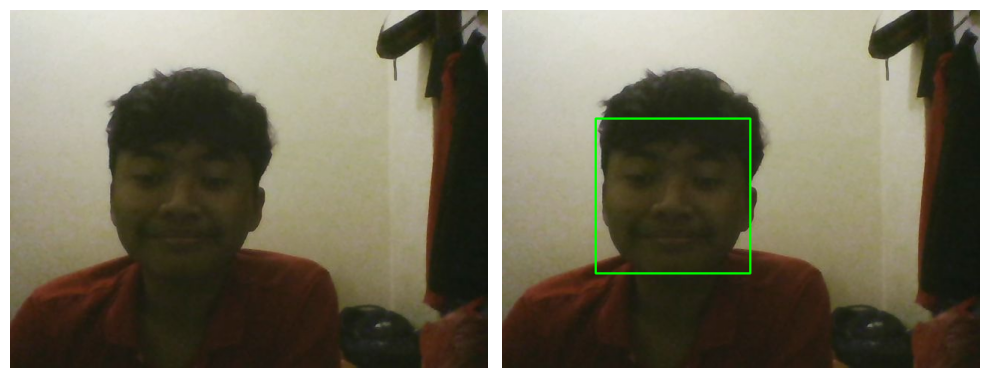

Saved to photo.jpg


In [ ]:
def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
          const div = document.createElement('div');
          const capture = document.createElement('button');
          capture.textContent = 'Capture';
          div.appendChild(capture);

          const video = document.createElement('video');
          video.style.display = 'block';
          const stream = await navigator.mediaDevices.getUserMedia({video: true});

          document.body.appendChild(div);
          div.appendChild(video);
          video.srcObject = stream;
          await video.play();

          google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
          await new Promise((resolve) => capture.onclick = resolve);

          const canvas = document.createElement('canvas');
          canvas.width = video.videoWidth;
          canvas.height = video.videoHeight;
          canvas.getContext('2d').drawImage(video, 0, 0);
          stream.getVideoTracks()[0].stop();
          div.remove();
          return canvas.toDataURL('image/jpeg', quality);
        }
    ''')
    display(js)

    data = eval_js('takePhoto({})'.format(quality))
    img = js_to_image(data)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    faces = detect_faces(gray)
    out = img.copy()
    t = max(2, int(min(out.shape[:2]) / 250))
    for (x, y, w, h) in faces:
        cv.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), t)

    cv.imwrite(filename, out)
    print(f"{len(faces)} wajah terdeteksi")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)); axes[0].axis("off")
    axes[1].imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB)); axes[1].axis("off")
    plt.tight_layout()
    plt.show()
    return filename

try:
    filename = take_photo('photo.jpg')
    print('Saved to {}'.format(filename))
except Exception as err:
    print(str(err))

In [ ]:
def video_stream():
    js = Javascript('''
        var video;
        var div = null;
        var stream;
        var captureCanvas;
        var imgElement;
        var labelElement;

        var pendingResolve = null;
        var shutdown = false;

        function removeDom() {
           stream.getVideoTracks()[0].stop();
           video.remove();
           div.remove();
           video = null;
           div = null;
           stream = null;
           imgElement = null;
           captureCanvas = null;
           labelElement = null;
        }

        function onAnimationFrame() {
          if (!shutdown) {
            window.requestAnimationFrame(onAnimationFrame);
          }
          if (pendingResolve) {
            var result = "";
            if (!shutdown) {
              captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
              result = captureCanvas.toDataURL('image/jpeg', 0.8)
            }
            var lp = pendingResolve;
            pendingResolve = null;
            lp(result);
          }
        }

        async function createDom() {
          if (div !== null) {
            return stream;
          }

          div = document.createElement('div');
          div.style.border = '2px solid black';
          div.style.padding = '3px';
          div.style.width = '100%';
          div.style.maxWidth = '600px';
          document.body.appendChild(div);

          const modelOut = document.createElement('div');
          modelOut.innerHTML = "<span>Status:</span>";
          labelElement = document.createElement('span');
          labelElement.innerText = 'No data';
          labelElement.style.fontWeight = 'bold';
          modelOut.appendChild(labelElement);
          div.appendChild(modelOut);

          video = document.createElement('video');
          video.style.display = 'block';
          video.width = div.clientWidth - 6;
          video.setAttribute('playsinline', '');
          video.onclick = () => { shutdown = true; };
          stream = await navigator.mediaDevices.getUserMedia(
              {video: { facingMode: "user"}});
          div.appendChild(video);

          imgElement = document.createElement('img');
          imgElement.style.position = 'absolute';
          imgElement.style.zIndex = 1;
          imgElement.onclick = () => { shutdown = true; };
          div.appendChild(imgElement);

          const instruction = document.createElement('div');
          instruction.innerHTML =
              '<span style="color: red; font-weight: bold;">' +
              'Klik di sini atau pada video untuk berhenti</span>';
          div.appendChild(instruction);
          instruction.onclick = () => { shutdown = true; };

          video.srcObject = stream;
          await video.play();

          captureCanvas = document.createElement('canvas');
          captureCanvas.width = 640;
          captureCanvas.height = 480;
          window.requestAnimationFrame(onAnimationFrame);

          return stream;
        }

        async function stream_frame(label, imgData) {
          if (shutdown) {
            removeDom();
            shutdown = false;
            return '';
          }

          var preCreate = Date.now();
          stream = await createDom();

          var preShow = Date.now();
          if (label != "") {
            labelElement.innerHTML = label;
          }

          if (imgData != "") {
            var videoRect = video.getClientRects()[0];
            imgElement.style.top = videoRect.top + "px";
            imgElement.style.left = videoRect.left + "px";
            imgElement.style.width = videoRect.width + "px";
            imgElement.style.height = videoRect.height + "px";
            imgElement.src = imgData;
          }

          var preCapture = Date.now();
          var result = await new Promise(function(resolve, reject) {
            pendingResolve = resolve;
          });
          shutdown = false;

          return {'create': preShow - preCreate,
                  'show': preCapture - preShow,
                  'capture': Date.now() - preCapture,
                  'img': result};
        }
    ''')
    display(js)

def video_frame(label, bbox):
    return eval_js('stream_frame("{}", "{}")'.format(label, bbox))

In [ ]:
video_stream()
label_html = 'Mendeteksi wajah...'
bbox = ''

while True:
    js_reply = video_frame(label_html, bbox)
    if not js_reply:
        break

    img = js_to_image(js_reply["img"])
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    faces = detect_faces(gray)

    bbox_array = np.zeros([480, 640, 4], dtype=np.uint8)
    for (x, y, w, h) in faces:
        cv.rectangle(bbox_array, (x, y), (x + w, y + h), (0, 255, 0, 255), 2)
    bbox_array[:, :, 3] = (bbox_array.max(axis=2) > 0).astype(int) * 255

    bbox = bbox_to_bytes(bbox_array)
    label_html = f'Wajah terdeteksi: {len(faces)}'

<IPython.core.display.Javascript object>

/tmp/ipykernel_16365/3387184673.py:26: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  bbox_pil = PILImage.fromarray(bbox_array, 'RGBA')


## 13.Lakukan Blurring pada bagian wajah yang terdeteksi. Berikut contoh keluaran yang diharapkan. Petunjuk: anda dapat menggunakan cv.medianBlur untuk melakukan Blurring

1 wajah terdeteksi


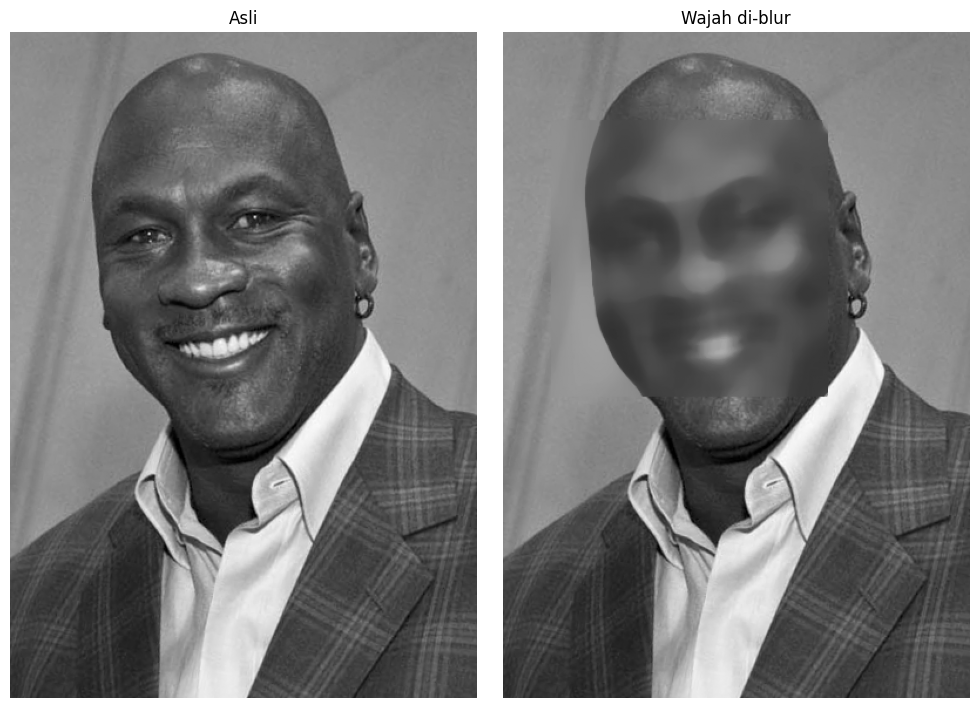

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
KERNEL = 25

face_cascade = cv.CascadeClassifier(cv.data.haarcascades + "haarcascade_frontalface_alt2.xml")
assert not face_cascade.empty(), "Gagal memuat cascade wajah"

img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/Images Object Detection/Michael_Jordan.jpg', 0)
assert img is not None, "Gagal membaca gambar"

faces = face_cascade.detectMultiScale(img, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))
print(f"{len(faces)} wajah terdeteksi")

blurred = img.copy()
for (x, y, w, h) in faces:
    roi = blurred[y:y + h, x:x + w]
    blurred[y:y + h, x:x + w] = cv.medianBlur(roi, KERNEL)

fig, axes = plt.subplots(1, 2, figsize=(10, 7))
axes[0].imshow(img, cmap="gray");     axes[0].set_title("Asli");       axes[0].axis("off")
axes[1].imshow(blurred, cmap="gray"); axes[1].set_title("Wajah di-blur"); axes[1].axis("off")
plt.tight_layout()
plt.show()

## 14.Mengolah gambar KTM masing-masing

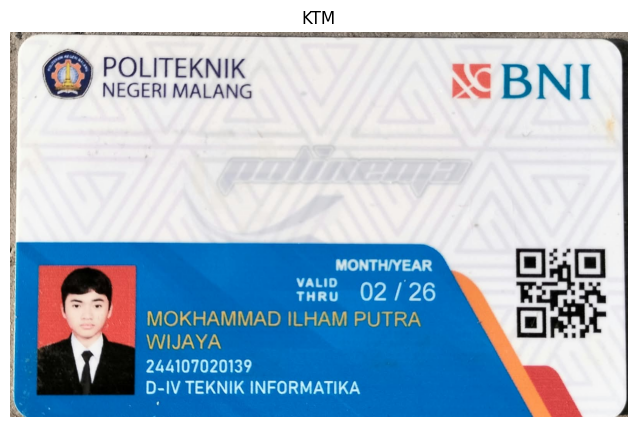

In [ ]:
def show(img_bgr, title="", figsize=(8, 5)):
    plt.figure(figsize=figsize)
    plt.imshow(cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB))
    plt.title(title); plt.axis("off")
    plt.show()
ktm = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/KTM1d.jpeg')
assert ktm is not None, "Gagal membaca KTM"
show(ktm, "KTM")

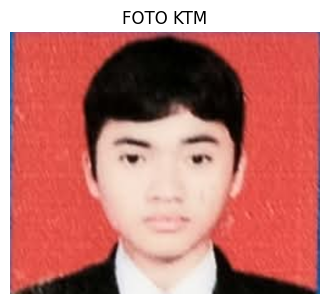

In [ ]:
hsv = cv.cvtColor(ktm, cv.COLOR_BGR2HSV)

mask = cv.bitwise_or(cv.inRange(hsv, (0, 120, 120), (10, 255, 255)), cv.inRange(hsv, (170, 120, 120), (180, 255, 255)))
mask = cv.morphologyEx(mask, cv.MORPH_CLOSE, cv.getStructuringElement(cv.MORPH_RECT, (25, 25)))

cnts, _ = cv.findContours(mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
x, y, w, h = cv.boundingRect(max(cnts, key=cv.contourArea))

foto = ktm[y:y + h, x:x + w]
foto = cv.resize(foto, None, fx=4, fy=4, interpolation=cv.INTER_CUBIC)

plt.figure(figsize=(4, 4))
plt.imshow(cv.cvtColor(foto, cv.COLOR_BGR2RGB))
plt.title("FOTO KTM")
plt.axis("off")
plt.show()

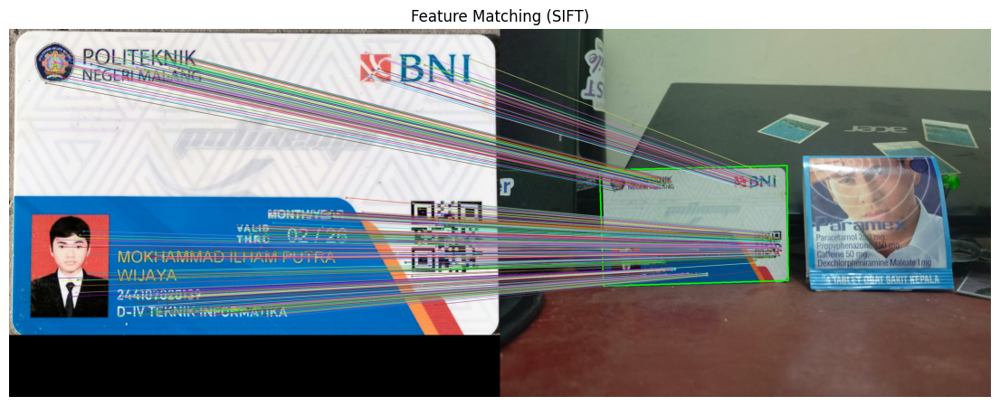

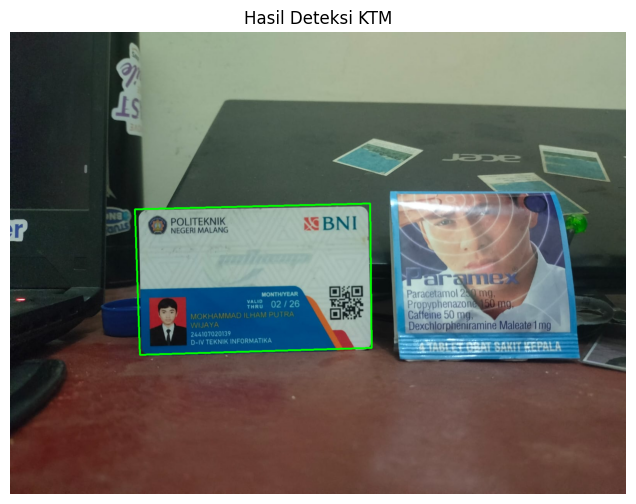

In [ ]:
scene = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/ktm_lain.jpeg')
assert scene is not None, "Gagal membaca gambar scene"

gray_ktm   = cv.cvtColor(ktm,   cv.COLOR_BGR2GRAY)
gray_scene = cv.cvtColor(scene, cv.COLOR_BGR2GRAY)

sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(gray_ktm,   None)
kp2, des2 = sift.detectAndCompute(gray_scene, None)

bf = cv.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)
good = [m for m, n in matches if m.distance < 0.75 * n.distance]

MIN_MATCH = 10
if len(good) >= MIN_MATCH:
    src_pts = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, inliers = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)

    hh, ww = gray_ktm.shape
    corners = np.float32([[0, 0], [0, hh - 1], [ww - 1, hh - 1], [ww - 1, 0]]).reshape(-1, 1, 2)
    box = cv.perspectiveTransform(corners, H)

    hasil = cv.polylines(scene.copy(), [np.int32(box)], True, (0, 255, 0), 4)
    inlier_mask = inliers.ravel().tolist()
else:
    print(f"KTM tidak ditemukan (match {len(good)} < {MIN_MATCH})")
    hasil, inlier_mask = scene.copy(), None

garis = cv.drawMatches(ktm, kp1, hasil, kp2, good, None, matchesMask=inlier_mask, flags=2)
show(garis, "Feature Matching (SIFT)", figsize=(14, 6))
show(hasil, "Hasil Deteksi KTM", figsize=(8, 6))

# D3. Tugas Pengayaan : Pengenalan Karakter KTM dengan CNN



In [ ]:
import os, shutil, random, pickle
import matplotlib.font_manager as fm
from PIL import Image, ImageDraw, ImageFont

NIM_BOX  = (129, 141, 60, 110)
CHARS = "0123456789"
N_PER_CLASS = 300
random.seed(0); np.random.seed(0)

In [ ]:
def get_fonts():
    ok = []
    for p in fm.findSystemFonts(fontext="ttf"):
        n = os.path.basename(p).lower()
        if any(s in n for s in ("italic", "oblique", "symbol", "dingbat", "webdings", "wingdings", "emoji", "mono", "cjk", "stix", "ocr")):
            continue
        try:
            f = ImageFont.truetype(p, 48)
            ims = []
            for c in "018":
                im = Image.new("L", (64, 64), 0)
                ImageDraw.Draw(im).text((8, 4), c, fill=255, font=f)
                ims.append(np.array(im))
            if (ims[0] != ims[1]).any() and (ims[1] != ims[2]).any() and ims[0].sum() > 0:
                ok.append(p)
        except Exception:
            pass
    return ok

def normalize_bw(bw, size=100, pad=0.15):
    ys, xs = np.where(bw > 0)
    if len(ys) == 0:
        return np.zeros((size, size), np.uint8)
    c = bw[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = c.shape
    s = int(max(h, w) * (1 + 2 * pad))
    sq = np.zeros((s, s), np.uint8)
    sq[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = c
    return cv.resize(sq, (size, size), interpolation=cv.INTER_AREA)

def render_digit(ch, font_path):
    f = ImageFont.truetype(font_path, random.randint(40, 60))
    im = Image.new("L", (96, 96), 0)
    ImageDraw.Draw(im).text((18, 10), ch, fill=255, font=f)
    a = np.array(im)
    ys, xs = np.where(a > 0)
    a = a[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = a.shape
    sh = random.uniform(-0.15, 0.15)
    a = cv.warpAffine(a, np.float32([[1, sh, 0], [0, 1, 0]]), (w + int(abs(sh) * h) + 2, h))
    R = cv.getRotationMatrix2D((a.shape[1] / 2, a.shape[0] / 2), random.uniform(-6, 6), 1)
    a = cv.warpAffine(a, R, (a.shape[1], a.shape[0]))
    th = random.randint(6, 10)
    tw = max(3, int(a.shape[1] * th / a.shape[0] * random.uniform(0.8, 1.2)))
    a = cv.resize(a, (tw, th), interpolation=cv.INTER_AREA)
    canvas = np.zeros((th + 6, tw + 8), np.uint8)
    canvas[3:3 + th, 4:4 + tw] = a
    return cv.add(canvas, np.random.randint(0, 25, canvas.shape, dtype=np.uint8))

def to_char_image(small, up=8):
    g = cv.resize(small, None, fx=up, fy=up, interpolation=cv.INTER_CUBIC)
    g = cv.GaussianBlur(g, (0, 0), up / 4)
    _, bw = cv.threshold(g, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    return normalize_bw(bw)

def segment_digits(ktm_bgr, box=NIM_BOX, n_expected=10, up=8):
    y1, y2, x1, x2 = box
    g = cv.cvtColor(ktm_bgr[y1:y2, x1:x2], cv.COLOR_BGR2GRAY)
    g = cv.resize(g, None, fx=up, fy=up, interpolation=cv.INTER_CUBIC)
    g = cv.GaussianBlur(g, (0, 0), up / 4)
    _, bw = cv.threshold(g, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    ys, xs = np.where(bw > 0)
    bw = bw[ys.min():ys.max() + 1, :]
    cols = (bw > 0).sum(0)

    segs, inside = [], False
    for i, v in enumerate(cols):
        if v > 0 and not inside: s = i; inside = True
        if v == 0 and inside: segs.append([s, i]); inside = False
    if inside: segs.append([s, len(cols)])

    while len(segs) < n_expected:
        j = int(np.argmax([b - a for a, b in segs])); a, b = segs[j]
        if b - a < 8: break
        lo, hi = a + int((b - a) * 0.3), a + int((b - a) * 0.7)
        cut = lo + int(np.argmin(cols[lo:hi]))
        segs[j:j + 1] = [[a, cut], [cut, b]]
    return bw, segs

In [ ]:
fonts = get_fonts()
print(len(fonts), "font dipakai")
assert len(fonts) >= 5, "Font terlalu sedikit"

OUT = "dataset/training"
if os.path.exists(OUT): shutil.rmtree(OUT)
for ch in CHARS:
    os.makedirs(f"{OUT}/{ch}")
    for i in range(N_PER_CLASS):
        img = to_char_image(render_digit(ch, random.choice(fonts)))
        cv.imwrite(f"{OUT}/{ch}/{ch}_{i:04d}.png", img)
print("dataset training selesai")

5 font dipakai
dataset training selesai


In [ ]:
from tqdm import tqdm

DATADIR = "dataset/training"
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv.imread(os.path.join(path, img), cv.IMREAD_GRAYSCALE)
            new_array = cv.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

9: 100%|██████████| 300/300 [00:00<00:00, 4036.63it/s]


jumlah data : 3000
jumlah kelas: 10 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [ ]:
from keras.layers import (Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64,  activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print("akurasi training :", riwayat.history['accuracy'][-1])
print("akurasi validasi :", riwayat.history['val_accuracy'][-1])

Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 55s 694ms/step - accuracy: 0.8100 - loss: 0.8523 - val_accuracy: 0.9950 - val_loss: 0.0396
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 72s 570ms/step - accuracy: 0.9837 - loss: 0.0435 - val_accuracy: 0.9933 - val_loss: 0.0238
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 82s 567ms/step - accuracy: 0.9908 - loss: 0.0282 - val_accuracy: 0.9983 - val_loss: 0.0088
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 43s 575ms/step - accuracy: 0.9946 - loss: 0.0172 - val_accuracy: 0.9950 - val_loss: 0.0124
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 82s 579ms/step - accuracy: 0.9942 - loss: 0.0146 - val_accuracy: 0.9983 - val_loss: 0.0049
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 80s 553ms/step - accuracy: 0.9996 - loss: 0.0041 - val_accuracy: 0.9983 - val_loss: 0.0063
Epoch 7/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 43s 574ms/step - accuracy: 0.9975 - loss: 0.0123 - val_accuracy: 0.9983 - val_loss: 0.0061
Epoch 8/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 44s 595ms/step - accuracy: 0.9983 - loss: 0.0038 - val_accu

In [ ]:
ktm = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/KTM1d.jpeg')
assert ktm is not None, "Gagal membaca KTM"

bw, segs = segment_digits(ktm)

OUT_TEST = "dataset/testing/NIM"
if os.path.exists("dataset/testing"): shutil.rmtree("dataset/testing")
os.makedirs(OUT_TEST)

for i, (a, b) in enumerate(segs):
    cv.imwrite(f"{OUT_TEST}/{i:02d}.png", normalize_bw(bw[:, a:b]))
print(len(segs), "karakter disimpan")

10 karakter disimpan


In [ ]:
import tensorflow as tf

data_dir_testing = "dataset/testing"
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs  = pickle.load(open("kelas.pickle", "rb"))

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv.imread(os.path.join(folder, char_img), cv.IMREAD_GRAYSCALE)
        new_array = cv.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
    print("folder name: {} no: {}".format(car, temp))

folder name: NIM no: 1181881112


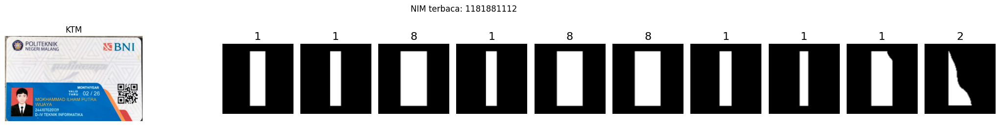

In [ ]:
folder = "dataset/testing/NIM"
files = sorted(os.listdir(folder))
hasil = ""

fig, axes = plt.subplots(1, len(files) + 1, figsize=(2 * (len(files) + 1), 2.6), gridspec_kw={"width_ratios": [4] + [1] * len(files)})
axes[0].imshow(cv.cvtColor(ktm, cv.COLOR_BGR2RGB))
axes[0].set_title("KTM"); axes[0].axis("off")

for ax, f in zip(axes[1:], files):
    img = cv.imread(os.path.join(folder, f), cv.IMREAD_GRAYSCALE)
    pred = model.predict(cv.resize(img, (100, 100)).reshape(-1, 100, 100, 1) / 255.0, verbose=0)
    label = dirs[np.argmax(pred[0])]
    hasil += label
    ax.imshow(img, cmap="gray")
    ax.set_title(label, fontsize=16)
    ax.axis("off")

plt.suptitle(f"NIM terbaca: {hasil}")
plt.tight_layout()
plt.show()